[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L6/BA_L6_pegquality/BA_L6_pegquality.ipynb)

# BA_L6_pegquality: Two tiers of peg quality

*Quantlet of Lecture 6, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Distribution of the absolute reference-adjusted deviation from the peg of 10 stablecoins (EODHD daily closes, January 2020 - May 2026), shown as box plots on a log scale, coins ordered by their median.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Two tiers of peg quality

The ten stablecoins are Tether (USDT), USD Coin (USDC), Dai (DAI), TrueUSD (TUSD), Pax Dollar (USDP), Gemini Dollar (GUSD), Binance USD (BUSD), Synthetix USD (sUSD), Pax Gold (PAXG) and STASIS Euro (EURS).

**Reference adjustment.** Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset ($B = 1$ for dollar tokens, EUR/USD for STASIS Euro (EURS), XAU/USD for Pax Gold (PAXG)). The reference-adjusted deviation, in basis points (bp, 0.01%), is
$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right). $$
Prices are put on a calendar of all days and filled from the past for at most 7 days; a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error and removed.

**How to read the chart.** One box per coin: the box is the interquartile range of $|d_{i,t}|$, the red line the median, the whiskers the 5% and 95% quantiles; log scale, January 2020 – May 2026 (the paper's sample period).

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


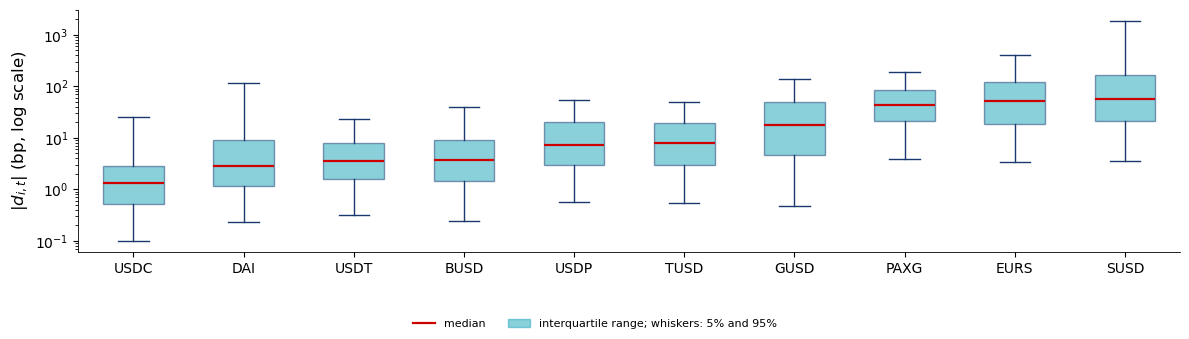

In [5]:
Dp = D.loc[:END_PAPER]
order = Dp.abs().median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 3.4))
bp_ = ax.boxplot([Dp[c].dropna().abs().clip(lower=0.1).values for c in order], whis=(5, 95), showfliers=False,
                 patch_artist=True, widths=0.55)
for b in bp_['boxes']:
    b.set(facecolor=TEAL, alpha=0.5, edgecolor=BLUE)
for k in ['whiskers', 'caps']:
    for l in bp_[k]:
        l.set(color=BLUE)
for l in bp_['medians']:
    l.set(color=RED, lw=1.6)
ax.set_yscale('log'); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
ax.set_ylabel(r'$|d_{i,t}|$ (bp, log scale)')
ax.plot([], [], color=RED, lw=1.6, label='median')
ax.fill_between([], [], color=TEAL, alpha=0.5, label='interquartile range; whiskers: 5% and 95%')
finish_fig(fig, 'ba_l6_pegquality', 0.13, ncol=2)

In [6]:
Q = pd.DataFrame({c: {'median |d| (bp)': Dp[c].dropna().abs().median(), '95% quantile of |d| (bp)': Dp[c].dropna().abs().quantile(0.95),
                      '5% quantile of d (bp)': Dp[c].dropna().quantile(0.05), '% of days with d <= -100 bp': 100 * (Dp[c].dropna() <= -100).mean(),
                      'days': Dp[c].notna().sum()} for c in order}).T
print('Peg quality, 1 January 2020 - 31 May 2026')
Q.round(2)

Peg quality, 1 January 2020 - 31 May 2026


,median |d| (bp),95% quantile of |d| (bp),5% quantile of d (bp),% of days with d <= -100 bp,days
USDC,1.32,25.81,-5.00,0.17,2343.0
DAI,2.80,114.40,-8.98,0.68,2343.0
USDT,3.55,23.24,-11.25,0.09,2343.0
BUSD,3.67,39.11,-8.64,0.09,2343.0
USDP,7.29,54.45,-47.47,0.21,2343.0
TUSD,7.75,48.78,-37.78,2.09,2343.0
GUSD,17.70,139.28,-109.99,6.32,2343.0
PAXG,43.51,185.86,-124.41,9.13,2343.0
EURS,50.95,401.13,-251.88,17.11,2315.0
SUSD,56.32,1883.38,-1883.38,25.99,2343.0


The large dollar tokens stay within a few bp; small, non-dollar or crypto-collateralised tokens are tens of bp off, with deep lower tails. The 95% whisker spans three orders of magnitude, from about 25 bp for USDC to almost 2,000 bp for sUSD.